# This is the *T1* Section

In [12]:
# import all the libraries for the model
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler

In [13]:
# load the dataset from the csv file into the jupyter notebook
df = pd.read_csv("concrete.csv")
display(df.head())
df.info()
# give basic info for the dataset

,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Compressive_Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Cement                1030 non-null   float64
 1   Blast_Furnace_Slag    1030 non-null   float64
 2   Fly_Ash               1030 non-null   float64
 3   Water                 1030 non-null   float64
 4   Superplasticizer      1030 non-null   float64
 5   Coarse_Aggregate      1030 non-null   float64
 6   Fine_Aggregate        1030 non-null   float64
 7   Age                   1030 non-null   int64  
 8   Compressive_Strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.5 KB


In [14]:
# remove null values from the dataset
df = df.dropna()

In [15]:
# remove outliers using IQR
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
df = df[~((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).any(axis=1)]
# formula removes outliers as: 1.5 * IQR below Q1 and 1.5 * IQR above Q3

In [16]:
# feature scaling and normalization
X = df.drop("Compressive_Strength", axis=1)
y = df["Compressive_Strength"]
# standard scaler makes features have mean=0 and s.dev=1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X = pd.DataFrame(X_scaled, columns=X.columns)

In [17]:
# export the processed dataset to csv
df.to_csv('concrete_processed.csv', index=False)

# This is the *T2* Section

In [18]:
# do test/train split of 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [19]:
# apply linear regression on the dataset
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("model trained")

model trained


# This is the *T3* Section

In [20]:
# evaluate the model with r2, mean-squared-error, rmse, mean-absolute-error
r2 = r2_score(y_test, y_pred) # regression score
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
print(f"R² Score : {r2:.4f}")
print(f"RMSE     : {rmse:.4f}")
print(f"MAE      : {mae:.4f}")
print(f"MSE      : {mse:.4f}")

R² Score : 0.7417
RMSE     : 8.1955
MAE      : 6.3998
MSE      : 67.1659


In [21]:
# apply 5-fold cross validation
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=kfold,
    scoring="r2"
)
print("R² Scores for each fold:")
for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")
print("\n")
print(f"Average R2: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")

R² Scores for each fold:
Fold 1: 0.7417
Fold 2: 0.7651
Fold 3: 0.7709
Fold 4: 0.7680
Fold 5: 0.7748


Average R2: 0.7641
Standard Deviation: 0.0117


Equation: y = 10.1397x + 34.8295


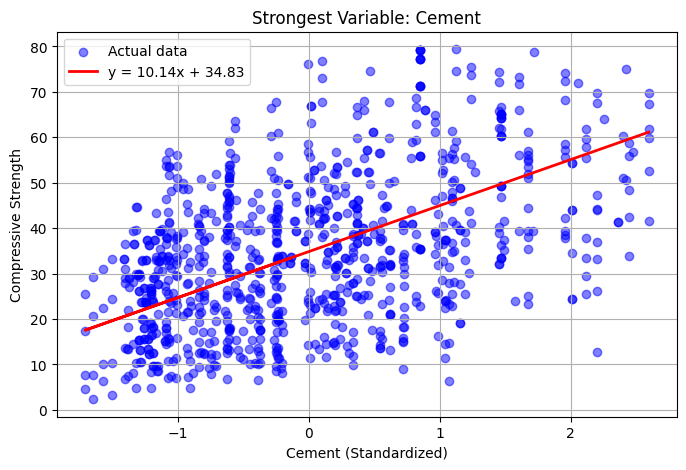

In [22]:
coefficients = pd.Series(model.coef_, index=X.columns)
strongest_variable = coefficients.abs().idxmax()
m = coefficients[strongest_variable]
c = model.intercept_
print(f"Equation: y = {m:.4f}x + {c:.4f}")
x = X[strongest_variable]
y_line = m * x + c
plt.figure(figsize=(8, 5))
plt.scatter(
    x,
    y,
    alpha=0.5,
    color="blue",
    label="Actual data"
)
plt.plot(
    x,
    y_line,
    color="red",
    linewidth=2,
    label=f"y = {m:.2f}x + {c:.2f}"
)
plt.xlabel(f"{strongest_variable} (Standardized)")
plt.ylabel("Compressive Strength")
plt.title(f"Strongest Variable: {strongest_variable}")
plt.legend()
plt.grid(True)
plt.show()